In [64]:
import pandas as pd
import glob
import os

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

# 1. Find all HTF result files
files = glob.glob("HTF_ALL_IN_ONE_*m.parquet")
if not files:
    print("No HTF parquet files found!")

print(f"Found {len(files)} files: {files}")

# 2. Combine them into one massive dataframe
df_list = [pd.read_parquet(f) for f in files]
df = pd.concat(df_list, ignore_index=True)

print(f"Total Combinations Loaded: {len(df):,}")

# ==========================================
# 3. GLOBAL FILTERS (Tweak these to your liking)
# ==========================================
# Must have enough data to be statistically significant
df = df[df["Total Trades"] >= 500]
df = df[df["2026 Trades"] >= 50]
df = df[df["Size Mult"] == 1.1]
df = df[df["Session"] == "US_Open"]

df = df[df["HTF Signal"] != "5 Min"]
df = df[df["TP Pts"] >= 5]
df = df[df["2022+ EV"] > 1]
#df = df[df['TP Pts'] > df['SL Pts']]  # Take Profit must be greater than Stop Loss
    
# Stop Loss must be large enough to not be instantly clipped by 1-min noise
#df = df[df["SL Pts"] >= 3.0]
#df = df[df["2026 EV"] > 0]  # Must be profitable in 2026 alone
#df = df[df["2022+ Win%"] >= 70]
df = df[(df["2026 Win%"] >= 70)]
df = df[(df["2025 Win%"] >= 70)]
df = df[(df["2024 Win%"] >= 70)]
df = df[(df["2023 Win%"] >= 60)]
df = df[(df["2022 Win%"] >= 60)]
df = df[(df["2021 Win%"] >= 60)]
df = df[(df["2020 Win%"] >= 60)]

# Positive Edge Filter
#df = df[df["Chronological EV"] > 0]

# ==========================================
# 4. SORT AND DISPLAY
# ==========================================
# Sort by the most profitable setups per trade
df = df.sort_values("2022+ Win%", ascending=False)

# Define columns to display to keep the console clean
# display_cols = [
#     'HTF Signal', 'Engulf Type', 'Session', 'Streak', 'Size Mult', 'Vol Filter',
#     'Hold Mins (1m)', 'TP Pts', 'SL Pts', 'Total Trades', 
#     'ALL Win%', 'ALL Loss%', 'ALL Timeout%', 
#     'Avg Window MFE (Pts)', 'Avg Window MAE (Pts)', 'Chronological EV'
# ]

df.head(50)

Found 4 files: ['HTF_ALL_IN_ONE_15m.parquet', 'HTF_ALL_IN_ONE_30m.parquet', 'HTF_ALL_IN_ONE_5m.parquet', 'HTF_ALL_IN_ONE_60m.parquet']
Total Combinations Loaded: 2,790,018


,Logic,HTF Signal,Engulf Type,Session,Trend,Vol Filter,Streak,Size Mult,Hold Mins,TP Pts,SL Pts,Total Trades,Wins (#),Win%,Losses (#),Loss%,Timeouts (#),Timeout%,Avg Trade MFE,Avg Trade MAE,Win Missed Potential,Timeout Max High (MFE),Timeout Max Low (MAE),Chronological EV,2022+ Trades,2022+ Wins (#),2022+ Win%,2022+ EV,2010 Trades,2010 Win%,2010 EV,2010 Avg MFE,2010 Avg MAE,2011 Trades,2011 Win%,2011 EV,2011 Avg MFE,2011 Avg MAE,2012 Trades,2012 Win%,2012 EV,2012 Avg MFE,2012 Avg MAE,2013 Trades,2013 Win%,2013 EV,2013 Avg MFE,2013 Avg MAE,2014 Trades,2014 Win%,2014 EV,2014 Avg MFE,2014 Avg MAE,2015 Trades,2015 Win%,2015 EV,2015 Avg MFE,2015 Avg MAE,2016 Trades,2016 Win%,2016 EV,2016 Avg MFE,2016 Avg MAE,2017 Trades,2017 Win%,2017 EV,2017 Avg MFE,2017 Avg MAE,2018 Trades,2018 Win%,2018 EV,2018 Avg MFE,2018 Avg MAE,2019 Trades,2019 Win%,2019 EV,2019 Avg MFE,2019 Avg MAE,2020 Trades,2020 Win%,2020 EV,2020 Avg MFE,2020 Avg MAE,2021 Trades,2021 Win%,2021 EV,2021 Avg MFE,2021 Avg MAE,2022 Trades,2022 Win%,2022 EV,2022 Avg MFE,2022 Avg MAE,2023 Trades,2023 Win%,2023 EV,2023 Avg MFE,2023 Avg MAE,2024 Trades,2024 Win%,2024 EV,2024 Avg MFE,2024 Avg MAE,2025 Trades,2025 Win%,2025 EV,2025 Avg MFE,2025 Avg MAE,2026 Trades,2026 Win%,2026 EV,2026 Avg MFE,2026 Avg MAE
177977,Normal,15 Min,wick,US_Open,All,All,1,1.1,15,5.0,50.0,1916,1253,65.4,41,2.1,622,32.5,17.74,17.93,20.51,2.32,9.91,-0.184,544,487,89.5,1.01,72,27.8,-3.30,3.86,3.93,99,38.4,-2.16,4.59,4.85,114,33.3,-2.70,4.11,4.36,123,27.6,-3.32,3.92,4.11,136,45.6,-1.38,5.38,6.42,128,58.6,0.03,7.41,7.37,119,51.3,-0.76,7.27,6.56,110,49.1,-1.00,6.25,5.66,115,75.7,1.87,15.08,14.09,107,78.5,2.18,11.38,9.63,129,85.3,1.54,24.18,25.09,120,85.8,0.02,25.80,29.02,126,88.1,-1.00,39.53,42.48,126,81.0,-0.36,24.64,27.71,120,90.8,2.40,30.92,30.70,117,96.6,3.00,45.06,41.36,55,94.5,1.50,51.48,47.78
181167,Normal,15 Min,wick,US_Open,All,All,1,1.1,10,5.0,50.0,1916,1170,61.1,36,1.9,710,37.1,14.90,15.32,17.74,2.28,8.65,-0.195,544,485,89.2,1.11,72,20.8,-3.32,3.10,3.25,99,32.3,-2.19,3.94,3.95,114,24.6,-2.95,3.47,3.60,123,20.3,-3.37,3.28,3.35,136,40.4,-1.39,4.56,5.51,128,53.1,-0.13,6.50,6.33,119,42.0,-1.23,6.08,5.37,110,40.9,-1.34,5.17,4.85,115,72.2,1.75,12.41,11.81,107,73.8,1.91,9.97,8.44,129,81.4,1.61,19.74,22.16,120,83.3,0.97,21.56,25.21,126,88.1,-0.97,35.51,35.90,126,80.2,0.03,20.64,24.25,120,90.8,2.47,26.42,26.67,117,95.7,2.92,36.16,35.04,55,94.5,1.50,41.75,38.89
162998,Normal,15 Min,wick,US_Open,All,All,1,1.1,5,5.0,50.0,1916,1005,52.5,27,1.4,884,46.1,11.04,11.02,14.06,2.17,6.55,-0.127,544,464,85.3,1.56,72,6.9,-3.27,2.27,2.17,99,14.1,-2.67,2.78,2.63,114,14.0,-2.68,2.57,2.46,123,8.9,-3.10,2.47,2.23,136,26.5,-1.64,3.31,3.78,128,40.6,-0.46,4.87,4.82,119,28.6,-1.46,4.17,3.64,110,30.0,-1.34,3.74,3.58,115,67.0,1.74,9.00,8.26,107,65.4,1.61,7.65,6.25,129,76.7,1.47,14.01,15.99,120,78.3,1.14,16.18,17.93,126,86.5,-0.70,26.55,27.43,126,74.6,2.01,14.82,17.29,120,83.3,2.33,20.11,19.62,117,93.2,2.73,26.77,25.26,55,94.5,1.50,32.17,25.66
170473,Normal,15 Min,wick,US_Open,All,All,1,1.1,5,5.0,45.0,1916,1002,52.3,35,1.8,879,45.9,11.04,11.02,13.99,2.17,6.32,-0.156,544,461,84.7,1.18,72,6.9,-3.09,2.27,2.17,99,14.1,-2.50,2.78,2.63,114,14.0,-2.51,2.57,2.46,123,8.9,-2.93,2.47,2.23,136,26.5,-1.50,3.31,3.78,128,40.6,-0.34,4.87,4.82,119,28.6,-1.33,4.17,3.64,110,30.0,-1.21,3.74,3.58,115,67.0,1.80,9.00,8.26,107,65.4,1.68,7.65,6.25,129,76.7,1.63,14.01,15.99,120,78.3,0.99,16.18,17.93,126,85.7,-0.98,26.55,27.43,126,74.6,1.43,14.82,17.29,120,82.5,1.68,20.11,19.62,117,92.3,2.44,26.77,25.26,55,94.5,1.77,32.17,25.66
147120,Normal,15 Min,wick,US_Open,All,All,1,1.1,3,5.0,50.0,1916,899,46.9,14,0.7,1003,52.3,8.85,8.64,11.62,1.98,5.80,-0.058,544,448,82.4,2.06,72,2.8,-3.22,1.96,1.69,99,10.1,-2.64,2.23,2.06,114,10.5,-2.60,2.19,1.82,123,3.3,-3.18,1.98,1.81,136,14.0,-2.33,2.53,3.03,128,35.2,-0.65,3.84,3.75,119,19.3,-1.90,3.19,2.93,110,20.9,-1.78,3.08,2.99,115,60.9,1.39,7.20,6.10,107,55.1,0.94,6.34,4.54,129,72.1,1.55,11.80,12.98,120,75.8,2.58,13.22,14.08,126

In [35]:
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

def compare_combinations():
    # Load your unified parquet file
    df = pd.read_parquet("HTF_ALL_IN_ONE_5m.parquet") 

    # ==========================================
    # ENTER THE PARAMETERS YOU WANT TO INSPECT
    # ==========================================
    target_params = {
        'Engulf Type': 'body',
        'Session': 'US_Open',
        'Trend': 'All',           # <--- ADDED THIS
        'Vol Filter': 'All',      # <--- ADDED THIS (Change to '1.5x' or '2x' if you want)
        'Streak': 1,
        'Size Mult': 1.1,
        'Hold Mins': 5,
        
        'Norm_TP': 20.0,
        'Norm_SL': 50.0
    }
    
    # Isolate Normal Row
    norm_row = df[
        (df['Logic'] == 'Normal') &
        (df['Engulf Type'] == target_params['Engulf Type']) &
        (df['Session'] == target_params['Session']) &
        (df['Trend'] == target_params['Trend']) &              # <--- ADDED THIS
        (df['Vol Filter'] == target_params['Vol Filter']) &    # <--- ADDED THIS
        (df['Streak'] == target_params['Streak']) &
        (df['Size Mult'] == target_params['Size Mult']) &
        (df['Hold Mins'] == target_params['Hold Mins']) &
        (df['TP Pts'] == target_params['Norm_TP']) &
        (df['SL Pts'] == target_params['Norm_SL'])
    ]

    # Isolate Inverse Row (Targets Swapped)
    inv_row = df[
        (df['Logic'] == 'Inverse') &
        (df['Engulf Type'] == target_params['Engulf Type']) &
        (df['Session'] == target_params['Session']) &
        (df['Trend'] == target_params['Trend']) &              # <--- ADDED THIS
        (df['Vol Filter'] == target_params['Vol Filter']) &    # <--- ADDED THIS
        (df['Streak'] == target_params['Streak']) &
        (df['Size Mult'] == target_params['Size Mult']) &
        (df['Hold Mins'] == target_params['Hold Mins']) &
        (df['TP Pts'] == target_params['Norm_SL']) &  
        (df['SL Pts'] == target_params['Norm_TP'])    
    ]

    if norm_row.empty or inv_row.empty:
        print("Could not find exact matching rows for those parameters in the dataset.")
        return

    # Combine and display
    compare_df = pd.concat([norm_row, inv_row])
    
    # Columns to highlight (Added Vol Filter so you know what you're looking at)
    display_cols = [
        'Logic', 'Vol Filter', 'TP Pts', 'SL Pts', 'Total Trades', 
        'Wins (#)', 'Win%', 'Losses (#)', 'Loss%', 'Timeouts (#)', 'Timeout%', 
        'Win Missed Potential', 'Timeout Max High (MFE)', 'Timeout Max Low (MAE)',
        'Chronological EV', '2022+ EV'
    ]

    print("\n================ SIDE-BY-SIDE LOGIC COMPARISON ================\n")
    print(compare_df[display_cols].to_string(index=False))
    print("\n===============================================================\n")

if __name__ == "__main__":
    compare_combinations()


================ SIDE-BY-SIDE LOGIC COMPARISON ================

  Logic Vol Filter  TP Pts  SL Pts  Total Trades  Wins (#)  Win%  Losses (#)  Loss%  Timeouts (#)  Timeout%  Win Missed Potential  Timeout Max High (MFE)  Timeout Max Low (MAE)  Chronological EV  2022+ EV
 Normal        All    20.0    50.0          5534       781  14.1          88    1.6          4665      84.3                 18.45                    4.98                   7.18             0.114      4.12
Inverse        All    50.0    20.0          5534        87   1.6         782   14.1          4665      84.3                 22.52                    7.18                   4.98            -1.126     -5.17




In [ ]:
import pandas as pd
test = pd.read_csv("HTF_verification_timeline_15.csv")
test = test.sort_values("HTF_Signal_Time", ascending=False)
test

,HTF_Signal_Time,LTF_Exec_Time,HTF_Signal,Direction_Traded,Entry_Price,Outcome,Exit_Time,Exit_Price,Window_MFE,Window_MAE,Missed_Potential
5533,2026-06-01 06:50:00-07:00,2026-06-01 06:55:00-07:00,Bearish Engulf,SHORT,30378.00,WIN,2026-06-01 06:55:00-07:00,30358.00,72.00,5.00,52.0
5532,2026-05-29 06:35:00-07:00,2026-05-29 06:40:00-07:00,Bullish Engulf,LONG,30428.50,WIN,2026-05-29 06:40:00-07:00,30448.50,33.50,5.50,13.5
5531,2026-05-27 07:15:00-07:00,2026-05-27 07:20:00-07:00,Bullish Engulf,LONG,30034.00,LOSS,2026-05-27 07:21:00-07:00,29984.00,9.00,72.25,0.0
5530,2026-05-27 07:05:00-07:00,2026-05-27 07:10:00-07:00,Bearish Engulf,SHORT,30022.50,WIN,2026-05-27 07:10:00-07:00,30002.50,40.00,8.25,20.0
5529,2026-05-25 07:20:00-07:00,2026-05-25 07:25:00-07:00,Bearish Engulf,SHORT,29949.75,TIMEOUT,2026-05-25 07:29:00-07:00,29942.25,9.75,2.50,0.0
...,...,...,...,...,...,...,...,...,...,...,...
4,2010-06-09 06:35:00-07:00,2010-06-09 06:40:00-07:00,Bearish Engulf,SHORT,1803.75,TIMEOUT,2010-06-09 06:44:00-07:00,1805.00,1.00,4.75,0.0
3,2010-06-08 07:25:00-07:00,2010-06-08 07:30:00-07:00,Bullish Engulf,LONG,1786.25,TIMEOUT,2010-06-08 07:34:00-07:00,1784.00,2.25,2.50,0.0
2,2010-06-08 06:30:00-07:00,2010-06-08 06:35:00-07:00,Bullish Engulf,LONG,1803.00,TIMEOUT,2010-06-08 06:39:00-07:00,1803.25,3.00,2.00,0.0
1,2010-06-07 06:45:00-07:00,2010-06-07 06:50:00-07:00,Bullish Engulf,LONG,1835.50,TIMEOUT,2010-06-07 06:54:00-07:00,1841.50,6.25,1.50,0.0



--- PERFORMANCE BY SIGNAL AND 10-MINUTE BIN ---
    HTF_Signal       Time_Bin  Total_Trades  Win_Rate_Pct  Avg_Potential_MFE  Avg_Drawdown_MAE
Bearish Engulf 2. 06:40-06:49           674         69.14          18.610534         18.770401
Bearish Engulf 4. 07:00-07:09            81         72.84          15.234568         14.320988
Bearish Engulf 5. 07:10-07:19           143         76.22          15.328671         15.758741
Bullish Engulf 2. 06:40-06:49           732         75.27          18.137637         19.148224
Bullish Engulf 4. 07:00-07:09            66         65.15          12.977273         11.378788
Bullish Engulf 5. 07:10-07:19            91         67.03          16.024725         14.733516

--- PERFORMANCE BY SIGNAL AND DAY OF THE WEEK ---
    HTF_Signal Day_of_Week  Total_Trades  Win_Rate_Pct  Avg_Potential_MFE  Avg_Drawdown_MAE
Bearish Engulf      Monday           142         73.94          18.644366         17.896127
Bearish Engulf     Tuesday           192         71

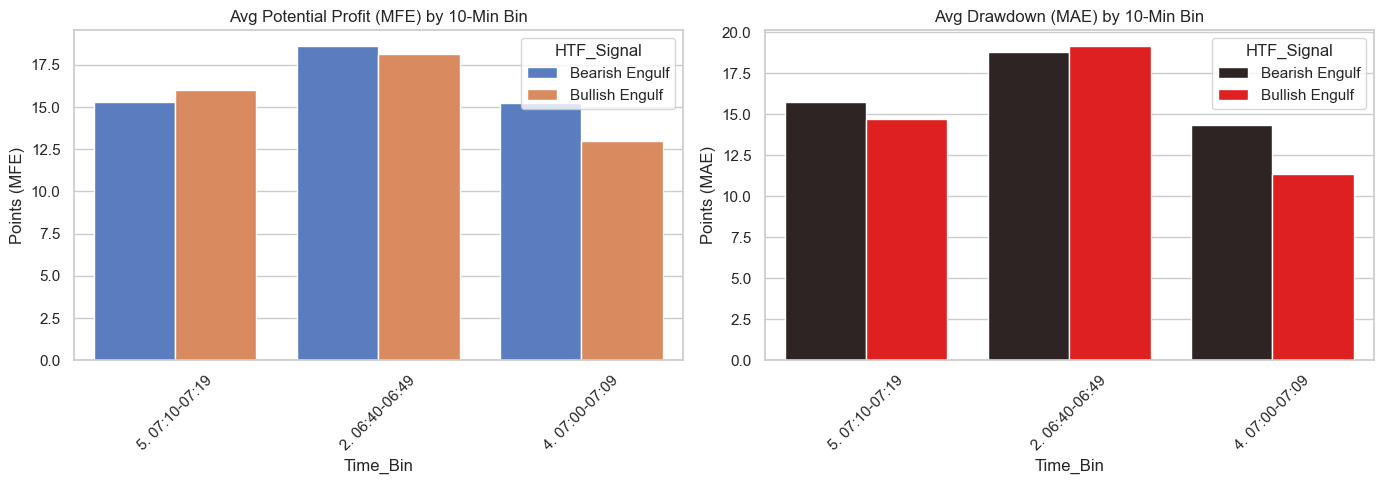

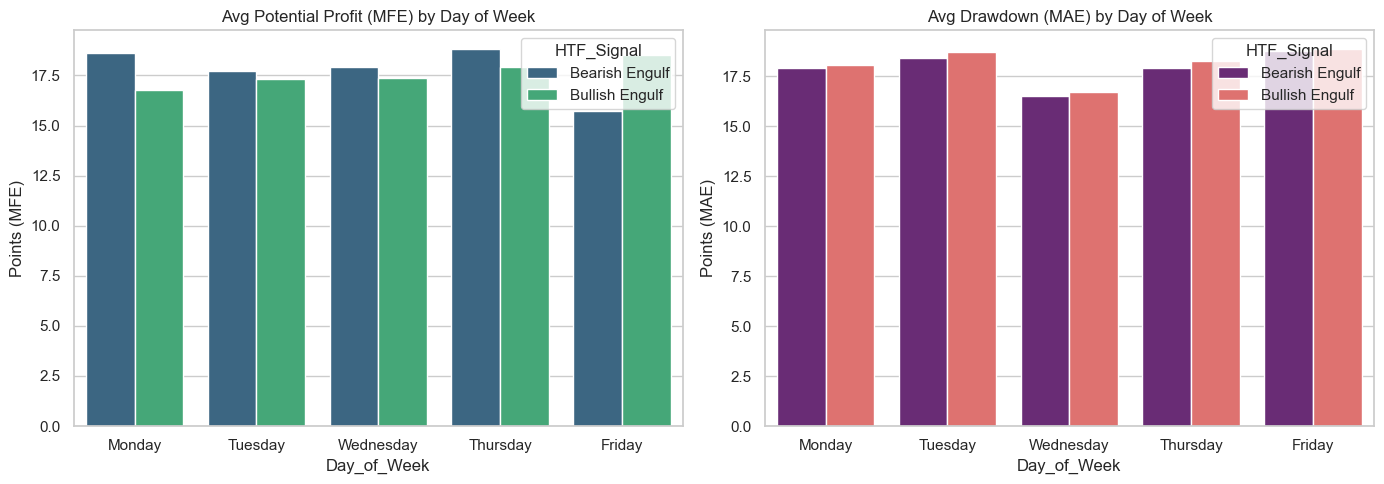


--- ARE WE LEAVING MONEY ON THE TABLE? ---


,HTF_Signal,Avg_MFE,Avg_Realized,Points_Lost_To_Timeouts
0,Bearish Engulf,17.783408,0.005568,17.78
1,Bullish Engulf,17.538245,0.687570,16.85


In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ==========================================
# STEP 1: Load the Data
# ==========================================
df = pd.read_csv("HTF_verification_timeline_15.csv")

# ==========================================
# STEP 2: The Time Fix (Robust Timezone Handling)
# ==========================================
# Instead of string slicing, we force Pandas to parse the ISO format with the offset, 
# standardize it to UTC, and then convert it locally to US/Pacific. 
# This perfectly handles -07:00 (PDT) and -08:00 (PST) automatically.

time_cols = ['HTF_Signal_Time', 'LTF_Exec_Time', 'Exit_Time']
for col in time_cols:
    df[col] = pd.to_datetime(df[col], utc=True).dt.tz_convert('US/Pacific')

# Sort data sequentially
df = df.sort_values("HTF_Signal_Time", ascending=False)

# ==========================================
# STEP 3: Feature Engineering - Points & Win/Loss
# ==========================================
df['Points_Realized'] = np.where(
    df['Direction_Traded'] == 'LONG',
    df['Exit_Price'] - df['Entry_Price'],
    df['Entry_Price'] - df['Exit_Price']
)
df['Is_Win'] = df['Points_Realized'] > 0

# ==========================================
# STEP 4: Create the Time Bins & Day of the Week
# ==========================================
def get_10min_bin(dt):
    if pd.isna(dt): return 'Unknown'
    hour, minute = dt.hour, dt.minute
    
    # We use US Open (06:30 - 07:30 PST)
    if hour == 6 and 30 <= minute < 40: return '1. 06:30-06:39'
    elif hour == 6 and 40 <= minute < 50: return '2. 06:40-06:49'
    elif hour == 6 and 50 <= minute < 60: return '3. 06:50-06:59'
    elif hour == 7 and 0 <= minute < 10:  return '4. 07:00-07:09'
    elif hour == 7 and 10 <= minute < 20: return '5. 07:10-07:19'
    elif hour == 7 and 20 <= minute < 30: return '6. 07:20-07:29'
    else: return '7. Outside Window'

# IMPORTANT: We apply the binning to LTF_Exec_Time. 
# If HTF is 15m, signals only happen at :00, :15, :30, :45. 
# Binning by execution time ensures we accurately see when the trade triggered!
df['Time_Bin'] = df['LTF_Exec_Time'].apply(get_10min_bin)
df = df[df['Time_Bin'] != '7. Outside Window'] # Keep only US Open 6:30-7:30 PST

# Add Day of the Week and order it logically (Mon-Fri)
# We base Day of the week on Execution time to be precise.
df['Day_of_Week'] = df['LTF_Exec_Time'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
df['Day_of_Week'] = pd.Categorical(df['Day_of_Week'], categories=days_order, ordered=True)

# ==========================================
# ANALYSIS & SUMMARY TABLES
# ==========================================

# 1. Summary by 10-Min Bin
summary_time = df.groupby(['HTF_Signal', 'Time_Bin'], observed=True).agg(
    Total_Trades=('HTF_Signal', 'count'),
    Win_Rate_Pct=('Is_Win', lambda x: (x.mean() * 100).round(2)),
    Avg_Potential_MFE=('Window_MFE', 'mean'),
    Avg_Drawdown_MAE=('Window_MAE', 'mean')
).reset_index()

# 2. Summary by Day of the Week
summary_day = df.groupby(['HTF_Signal', 'Day_of_Week'], observed=True).agg(
    Total_Trades=('HTF_Signal', 'count'),
    Win_Rate_Pct=('Is_Win', lambda x: (x.mean() * 100).round(2)),
    Avg_Potential_MFE=('Window_MFE', 'mean'),
    Avg_Drawdown_MAE=('Window_MAE', 'mean')
).reset_index()

# Using print() instead of display() so it runs safely in standard Python environments
print("\n--- PERFORMANCE BY SIGNAL AND 10-MINUTE BIN ---")
print(summary_time.to_string(index=False))

print("\n--- PERFORMANCE BY SIGNAL AND DAY OF THE WEEK ---")
print(summary_day.to_string(index=False))

# ==========================================
# VISUALIZATIONS
# ==========================================
sns.set_theme(style="whitegrid") # Adds a nice background to the charts

# FIGURE 1: 10-Minute Bins
fig1, axes1 = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x='Time_Bin', y='Window_MFE', hue='HTF_Signal', errorbar=None, palette='muted', ax=axes1[0])
axes1[0].set_title('Avg Potential Profit (MFE) by 10-Min Bin')
axes1[0].tick_params(axis='x', rotation=45)
axes1[0].set_ylabel('Points (MFE)')

sns.barplot(data=df, x='Time_Bin', y='Window_MAE', hue='HTF_Signal', errorbar=None, palette='dark:red', ax=axes1[1])
axes1[1].set_title('Avg Drawdown (MAE) by 10-Min Bin')
axes1[1].tick_params(axis='x', rotation=45)
axes1[1].set_ylabel('Points (MAE)')

plt.tight_layout()
plt.show()

# FIGURE 2: Day of the Week
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x='Day_of_Week', y='Window_MFE', hue='HTF_Signal', errorbar=None, palette='viridis', ax=axes2[0])
axes2[0].set_title('Avg Potential Profit (MFE) by Day of Week')
axes2[0].set_ylabel('Points (MFE)')

sns.barplot(data=df, x='Day_of_Week', y='Window_MAE', hue='HTF_Signal', errorbar=None, palette='magma', ax=axes2[1])
axes2[1].set_title('Avg Drawdown (MAE) by Day of Week')
axes2[1].set_ylabel('Points (MAE)')

plt.tight_layout()
plt.show()

# ==========================================
# MISSED POTENTIAL (TIMEOUTS)
# ==========================================
print("\n--- ARE WE LEAVING MONEY ON THE TABLE? ---")
missed_summary = df.groupby('HTF_Signal').agg(
    Avg_MFE=('Window_MFE', 'mean'),
    Avg_Realized=('Points_Realized', 'mean')
).reset_index()

missed_summary['Points_Lost_To_Timeouts'] = (missed_summary['Avg_MFE'] - missed_summary['Avg_Realized']).round(2)
display(missed_summary)